<a href="https://colab.research.google.com/github/Chepngetich/AI-for-Science-and-Engineering/blob/main/Discovering_Patterns_in_Data_Week6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6: Clustering Penguin Species Using Physical Measurements
**Project:** Unsupervised Machine Learning: Clustering Penguin Species Using Physical Measurements.

The objective is to investigate whether penguins can be grouped into meaningful clusters based on their physical measurements, without telling the clustering algorithm their species.

**Dataset source:** Palmer Penguins dataset from Hugging Face
https://huggingface.co/datasets/SIH/palmer-penguins


## 1. Load and inspect the dataset

The dataset contains 344 rows and eight columns, including four numerical measurements, species, island, sex and year.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = (
    "https://huggingface.co/datasets/SIH/"
    "palmer-penguins/resolve/main/penguins.csv"
)

df = pd.read_csv(url, na_values=["NA", ""])

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


## 2. Prepare the features

Prepare the features

In [2]:
from sklearn.preprocessing import StandardScaler

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

X = df[features].dropna()

# Keep matching species labels for interpretation only
species = df.loc[X.index, "species"].reset_index(drop=True)
X = X.reset_index(drop=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Samples retained:", len(X))
print("Features used:", features)

Samples retained: 342
Features used: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


## 3. Determine the appropriate number of clusters

Plot the elbow curve and Plot the silhouette scores

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Calculate inertia and silhouette scores for k from 2 to 10
ks = range(2, 11)
inertias = []
silhouette_scores = []

for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

results_df = pd.DataFrame({
    "k": ks,
    "inertia": inertias,
    "silhouette": silhouette_scores
})

display(results_df)

,k,inertia,silhouette
0,2,565.707645,0.531540
1,3,379.392503,0.447219
2,4,300.399536,0.399584
3,5,232.604895,0.378892
4,6,204.392600,0.367996
5,7,187.028921,0.330913
6,8,170.980041,0.296052
7,9,159.979975,0.279149
8,10,149.424376,0.283990


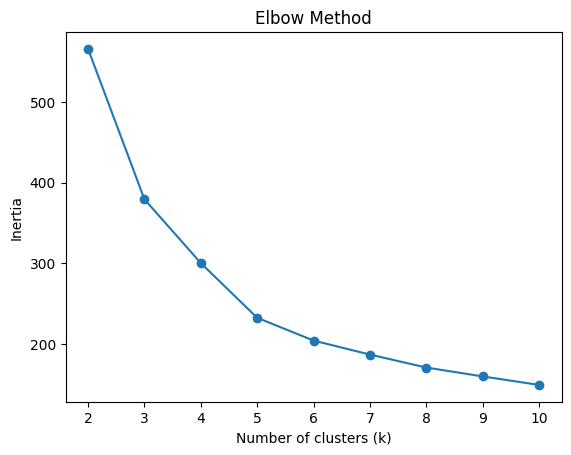

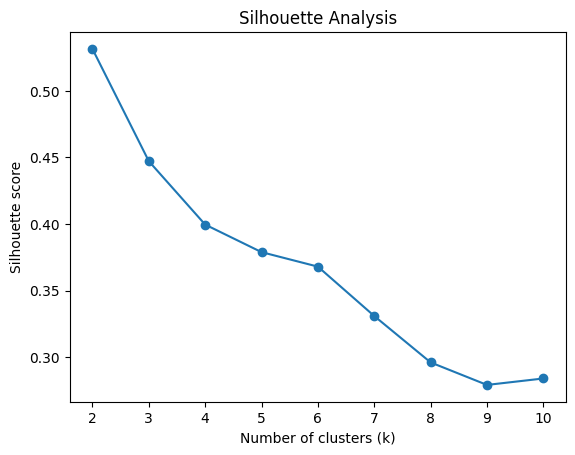

In [7]:
plt.plot(results_df["k"], results_df["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

plt.plot(results_df["k"], results_df["silhouette"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.show()

### Target, features, and problem type

- **Target/output (`y`):** genotype category at the selected target SNP.
- **Features (`X`):** genotype categories at other SNP markers.
- **Problem type:** classification, because genotype classes are discrete categories.
- **Evaluation:** the models predict held-out samples whose original target calls are known. This approximates the task of imputing hidden calls while retaining ground truth for evaluation.

## 4. Visualise the clusters

After choosing your \(k\), replace the value below with your selected number.
PCA is used here only to display the clusters in two dimensions; K-Means was fitted using all four standardised measurements.

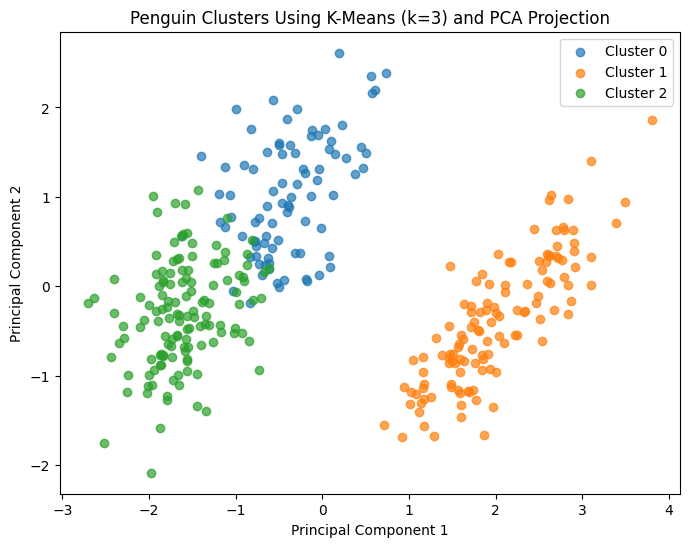

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Let's use the recommended 3 clusters based on the elbow / silhouette evaluation
best_k = 3
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Reduce features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(8, 6))
for cluster_id in sorted(np.unique(clusters)):
    mask = clusters == cluster_id
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Penguin Clusters Using K-Means (k=3) and PCA Projection")
plt.legend()
plt.show()

In [12]:
clustered_data = X.copy()
clustered_data["cluster"] = clusters

print("Number of penguins per cluster:")
display(clustered_data["cluster"].value_counts().sort_index())

print("Mean measurements by cluster:")
display(
    clustered_data.groupby("cluster")[features]
    .mean()
    .round(2)
)

Number of penguins per cluster:


,count
cluster,
0,87
1,123
2,132


Mean measurements by cluster:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,
0,47.53,18.76,196.90,3902.01
1,47.50,14.98,217.19,5076.02
2,38.21,18.11,188.40,3584.66


## 5. Describe the clusters
* **Cluster 1**  (The "Large & Heavy" Group): Home to giant penguins with
long flippers and heavy bodies (averaging over 5 kg). This perfectly isolates the Gentoo species.
* **Cluster 2**(The "Short & Stubby Bill" Group): Small and lightweight penguins (averaging appr 3.7 kg) defined by having exceptionally short but very deep bills. This captures the majority of Adelie penguins.
* **Cluster 0** (The "Long & Slender Bill" Group): Similarly lightweight (~3.7 kg) but physically distinct due to longer, slender bills. This group maps to almost all Chinstrap penguins alongside a few overlapping Adelie individuals.

## 6. compare the resulting clusters with the known species

In [11]:
comparison = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    species.rename("Known species")
)

display(comparison)

Known species,Adelie,Chinstrap,Gentoo
Cluster,,,
0,24,63,0
1,0,0,123
2,127,5,0


The comparison table is a cross-tabulation (contingency table) that directly measures how well our unsupervised K-Means clusters match the actual biological species of the penguins

**Cluster 1** is 100% clean. It contains 123 Gentoo penguins and absolutely no other species. This proves that Gentoo penguins have a highly distinct physical profile (larger body mass, longer flippers, and shallower bills) that the algorithm can separate with perfect accuracy.

**Cluster 2** captures 127 Adelie penguins and only includes 5 Chinstraps. The model successfully grouped the vast majority of Adelies together based on their characteristic short, stubby bills.

**Cluster 0** is a mixture. It contains almost all of the Chinstrap penguins (63), but it also pulled in 24 Adelie penguins.
This occurs because these 24 Adelie penguins share very similar body masses, flipper lengths, and bill structures to Chinstraps, leading to some physical overlap that standard clustering cannot perfectly split without species labels.